ANALYSIS QUESTION:
Is there a statistically significant difference in disciplinary behaviour between teams that advanced to the Round of 32 and teams that were eliminated during the FIFA World Cup 2026 group stage?

In [2]:
import pandas as pd

teams = pd.read_excel("teams(1).xlsx")
stats = pd.read_excel("match_team_stats(1).xlsx")
matches = pd.read_excel("matches_detailed.xlsx")

In [3]:
advanced_codes = [
    "MEX", "USA", "GER", "ARG",
    "SUI", "CAN", "BRA", "MAR",
    "NED", "FRA", "NOR", "COL",
    "BIH", "CIV", "ECU", "PAR",
    "RSA", "AUS", "JPN", "SWE",
    "BEL", "EGY", "ESP", "CPV",
    "SEN", "POR", "ENG", "CRO",
    "GHA", "ALG", "AUT", "COD"
]

In [4]:
#adding the status to teams table
teams["Advanced"] = teams["fifa_code"].apply(
    lambda code: "Yes" if code in advanced_codes else "No"
)

In [5]:
teams[["team_name", "group_letter", "fifa_code", "Advanced"]]

,team_name,group_letter,fifa_code,Advanced
0,Mexico,A,MEX,Yes
1,South Africa,A,RSA,Yes
2,South Korea,A,KOR,No
3,Czechia,A,CZE,No
4,Canada,B,CAN,Yes
5,Bosnia and Herzegovina,B,BIH,Yes
6,Qatar,B,QAT,No
7,Switzerland,B,SUI,Yes
8,Brazil,C,BRA,Yes
9,Morocco,C,MAR,Yes


In [6]:
#verifying the number of teams that advanced to the next round
teams["Advanced"].value_counts()

Advanced
Yes    32
No     16
Name: count, dtype: int64

In [7]:
group_matches = matches[
    matches["stage_name"] == "Group Stage"
]

group_match_ids = group_matches["match_id"]

In [8]:
#filtering the foul stats
group_stats = stats[
    stats["match_id"].isin(group_match_ids)
].copy()

In [9]:
group_stats.shape

(144, 12)

In [10]:
discipline_data = group_stats.merge(
    teams[
        ["team_id", "team_name", "group_letter", "fifa_code", "Advanced"]
    ],
    on="team_id",
    how="left"
)

In [11]:
discipline_data = discipline_data[
    [
        "match_id",
        "team_id",
        "team_name",
        "group_letter",
        "Advanced",
        "fouls"
    ]
]

In [12]:
discipline_data.head()

,match_id,team_id,team_name,group_letter,Advanced,fouls
0,1,1,Mexico,A,Yes,11
1,1,2,South Africa,A,Yes,15
2,2,3,South Korea,A,No,10
3,2,4,Czechia,A,No,13
4,3,5,Canada,B,Yes,12


In [ ]:
# EXPORTING THE DATA TO CSV
discipline_data.to_csv(
    "discipline_group_stage_data.csv",
    index=False
)

In [ ]:
# EXPORTING THE DATA TO EXCEL
discipline_data.to_excel(
    "discipline_group_stage_data.xlsx",
    index=False
)

In [15]:
team_discipline = discipline_data.groupby(
    ["team_id", "team_name", "group_letter", "Advanced"]
).agg(
    Matches_Played=("match_id", "count"),
    Total_Fouls=("fouls", "sum"),
    Mean_Fouls_Per_Match=("fouls", "mean")
).reset_index()

In [16]:
team_discipline

,team_id,team_name,group_letter,Advanced,Matches_Played,Total_Fouls,Mean_Fouls_Per_Match
0,1,Mexico,A,Yes,3,33,11.000000
1,2,South Africa,A,Yes,3,37,12.333333
2,3,South Korea,A,No,3,26,8.666667
3,4,Czechia,A,No,3,34,11.333333
4,5,Canada,B,Yes,3,31,10.333333
5,6,Bosnia and Herzegovina,B,Yes,3,41,13.666667
6,7,Qatar,B,No,3,36,12.000000
7,8,Switzerland,B,Yes,3,33,11.000000
8,9,Brazil,C,Yes,3,34,11.333333
9,10,Morocco,C,Yes,3,34,11.333333


In [17]:
team_discipline.shape

(48, 7)

In [18]:
# verifying that every team has exaclty 3 matches played in the group stage
team_discipline["Matches_Played"].value_counts()

Matches_Played
3    48
Name: count, dtype: int64

In [19]:
# verifying advancement split:
team_discipline["Advanced"].value_counts()

Advanced
Yes    32
No     16
Name: count, dtype: int64

In [20]:
team_discipline.isnull().sum()

team_id                 0
team_name               0
group_letter            0
Advanced                0
Matches_Played          0
Total_Fouls             0
Mean_Fouls_Per_Match    0
dtype: int64

In [21]:
# checking for duplicate teams
team_discipline["team_id"].duplicated().sum()

np.int64(0)

In [22]:
# checking whether any foul values look impossible
team_discipline[
    (team_discipline["Total_Fouls"] < 0) |
    (team_discipline["Mean_Fouls_Per_Match"] < 0)
]

,team_id,team_name,group_letter,Advanced,Matches_Played,Total_Fouls,Mean_Fouls_Per_Match


In [23]:
#inspecting the range:
team_discipline[
    ["Total_Fouls", "Mean_Fouls_Per_Match"]
].describe()

,Total_Fouls,Mean_Fouls_Per_Match
count,48.000000,48.000000
mean,31.895833,10.631944
std,5.691500,1.897167
min,15.000000,5.000000
25%,29.000000,9.666667
50%,32.500000,10.833333
75%,34.250000,11.416667
max,42.000000,14.000000


In [24]:
#CREATING SEPERATE DATASET FOR THE TEAMS THAT ADVANCED AND WERE ELIMINATED
advanced = team_discipline[
    team_discipline["Advanced"] == "Yes"
].copy()

eliminated = team_discipline[
    team_discipline["Advanced"] == "No"
].copy()

In [25]:
print("Advanced teams:", len(advanced))
print("Eliminated teams:", len(eliminated))

Advanced teams: 32
Eliminated teams: 16


In [26]:
# All 48 teams participating in the FIFA World Cup 2026 group
#  stage were included.
#  Each team was treated as one observational unit,
#  with fouls aggregated across its three group-stage matches.
#  Teams were then separated into Advanced (n = 32) and Eliminated (n = 16) groups.

In [27]:
# CALCUALTING DESCRIPTIVE STATISTICS FOR THE TWO GROUPS
descriptive_stats = team_discipline.groupby("Advanced")[
    "Mean_Fouls_Per_Match"
].agg(
    Count="count",
    Mean="mean",
    Median="median",
    Std_Dev="std",
    Minimum="min",
    Maximum="max"
)

descriptive_stats


,Count,Mean,Median,Std_Dev,Minimum,Maximum
Advanced,,,,,,
No,16,11.166667,11.000000,1.695309,8.666667,14.000000
Yes,32,10.364583,10.833333,1.960834,5.000000,13.666667


In [28]:
#rounding to 2 decimal places
descriptive_stats.round(2)

,Count,Mean,Median,Std_Dev,Minimum,Maximum
Advanced,,,,,,
No,16,11.17,11.00,1.70,8.67,14.00
Yes,32,10.36,10.83,1.96,5.00,13.67


Initially we could say: Eliminated teams committed more fouls per match on average than Advanced teams.
But that is only a descriptive observation, not yet evidence of a statistically significant difference.

In [29]:
# Calculating the difference in means between the two groups

advanced_mean = advanced["Mean_Fouls_Per_Match"].mean()
eliminated_mean = eliminated["Mean_Fouls_Per_Match"].mean()

mean_difference = advanced_mean - eliminated_mean

print("Advanced mean:", round(advanced_mean, 2))
print("Eliminated mean:", round(eliminated_mean, 2))
print("Difference:", round(mean_difference, 2))

Advanced mean: 10.36
Eliminated mean: 11.17
Difference: -0.8


Difference= mean(advanced) - mean(eliminated)​	
So:
positive difference → Advanced teams committed more fouls
negative difference → Eliminated teams committed more fouls
close to 0 → very similar averages

In [30]:
import sys
print(sys.executable)

/opt/anaconda3/envs/hit140env/bin/python


In [31]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.


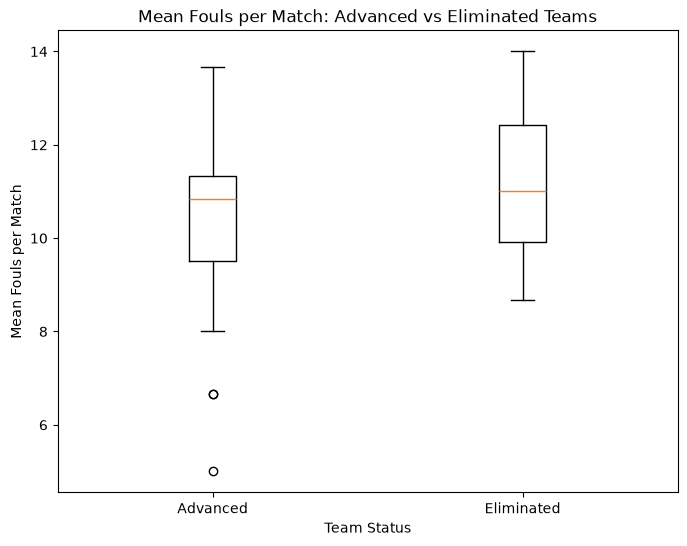

In [32]:
# MAKING A BOXPLOT

import matplotlib.pyplot as plt

data_to_plot = [
    advanced["Mean_Fouls_Per_Match"],
    eliminated["Mean_Fouls_Per_Match"]
]

plt.figure(figsize=(8, 6))

plt.boxplot(
    data_to_plot,
    tick_labels=["Advanced", "Eliminated"]
)

plt.title("Mean Fouls per Match: Advanced vs Eliminated Teams")
plt.xlabel("Team Status")
plt.ylabel("Mean Fouls per Match")

plt.show()

The boxplot shows that Advanced and Eliminated teams had similar median fouls per match, with substantial overlap between the two distributions. Eliminated teams showed a slightly higher central tendency, while the Advanced group contained two unusually low-foul outliers. This suggests that any difference in discipline between the groups may be small and should be tested using inferential statistics.

In [33]:
# CALCULATING 95% CONFIDENCE INTERVAL

import numpy as np
from scipy import stats

adv = advanced["Mean_Fouls_Per_Match"]
elim = eliminated["Mean_Fouls_Per_Match"]

# sample means
mean_adv = adv.mean()
mean_elim = elim.mean()

# mean difference
mean_diff = mean_adv - mean_elim

# sample variances
var_adv = adv.var(ddof=1)
var_elim = elim.var(ddof=1)

# sample sizes
n_adv = len(adv)
n_elim = len(elim)

# standard error for Welch's method
se = np.sqrt(
    (var_adv / n_adv) +
    (var_elim / n_elim)
)

# Welch-Satterthwaite degrees of freedom
df = (
    (var_adv / n_adv + var_elim / n_elim) ** 2
) / (
    ((var_adv / n_adv) ** 2 / (n_adv - 1)) +
    ((var_elim / n_elim) ** 2 / (n_elim - 1))
)

# critical t value for 95% CI
t_critical = stats.t.ppf(0.975, df)

# confidence interval
lower = mean_diff - t_critical * se
upper = mean_diff + t_critical * se

print("Advanced mean:", round(mean_adv, 3))
print("Eliminated mean:", round(mean_elim, 3))
print("Mean difference:", round(mean_diff, 3))
print(
    "95% CI:",
    (round(float(lower), 3), round(float(upper), 3))
)

Advanced mean: 10.365
Eliminated mean: 11.167
Mean difference: -0.802
95% CI: (-1.914, 0.31)


Advanced teams committed fewer fouls per match on average than Eliminated teams, with a mean difference of -0.802 fouls per match. However, the 95% confidence interval ranged from -1.914 to 0.310 fouls per match. Because the interval includes zero, the observed difference may be due to sampling variability and does not provide strong evidence of a true difference in discipline between the two groups.

In [34]:
# RUNNING WELCH'S TWO-SAMPLE T-TEST

from scipy import stats

t_stat, p_value = stats.ttest_ind(
    advanced["Mean_Fouls_Per_Match"],
    eliminated["Mean_Fouls_Per_Match"],
    equal_var=False
)

print("t-statistic:", round(t_stat, 3))
print("p-value:", round(p_value, 4))

t-statistic: -1.465
p-value: 0.152


Advanced teams committed an average of 10.365 fouls per match, compared with 11.167 for Eliminated teams. The mean difference was -0.802 fouls per match. However, the 95% confidence interval for the difference ranged from -1.914 to 0.310, and Welch’s two-sample t-test found no statistically significant difference between the groups, \(t=-1.465\), \(p=0.152\). Therefore, the analysis does not provide sufficient evidence that advancement status was associated with a difference in fouls committed during the group stage.

***** MORE VISUALIZATIONS ******

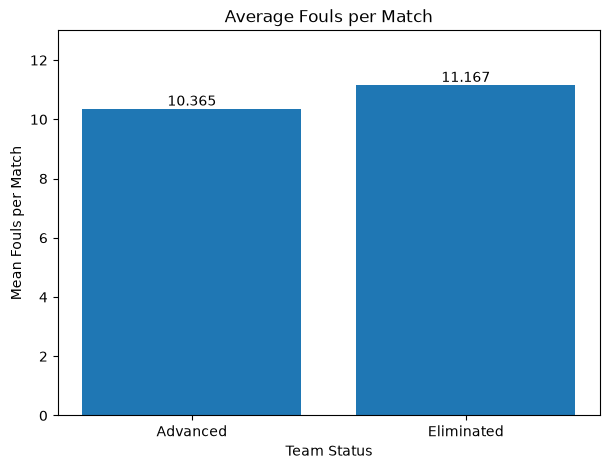

In [36]:
#MEAN FOULS BAR CHART

import matplotlib.pyplot as plt

means = [
    advanced["Mean_Fouls_Per_Match"].mean(),
    eliminated["Mean_Fouls_Per_Match"].mean()
]

plt.figure(figsize=(7, 5))

bars = plt.bar(
    ["Advanced", "Eliminated"],
    means
)

plt.title("Average Fouls per Match")
plt.xlabel("Team Status")
plt.ylabel("Mean Fouls per Match")

# Putting values on top of bars
for bar, value in zip(bars, means):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        value + 0.1,
        f"{value:.3f}",
        ha="center"
    )

plt.ylim(0, 13)
plt.show()

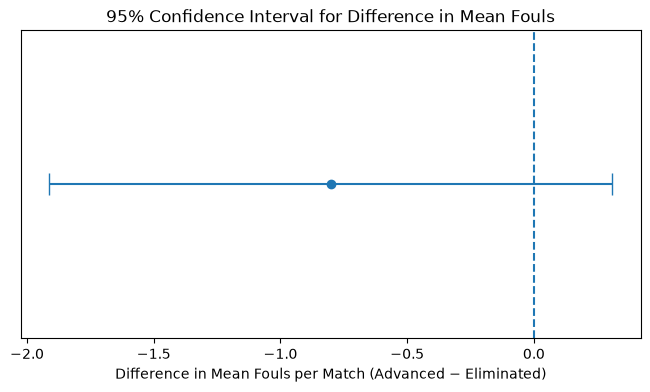

In [37]:
# 95%  CI plot

import matplotlib.pyplot as plt

mean_difference = -0.802
lower_ci = -1.914
upper_ci = 0.310

error_left = mean_difference - lower_ci
error_right = upper_ci - mean_difference

plt.figure(figsize=(8, 4))

plt.errorbar(
    mean_difference,
    1,
    xerr=[[error_left], [error_right]],
    fmt="o",
    capsize=8
)

# Zero = no difference
plt.axvline(
    x=0,
    linestyle="--"
)

plt.yticks([])
plt.xlabel("Difference in Mean Fouls per Match (Advanced − Eliminated)")
plt.title("95% Confidence Interval for Difference in Mean Fouls")

plt.show()